In [1]:
from run_experiment import run_experiment_single_class, build_dataloaders, build_model
from utils.visualization import visualize_anomalies
from utils.helpers import set_seed, get_device
from utils.data_split import split_data
from losses import MSELoss
import pandas as pd

W1107 19:17:18.174000 13108 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


In [ ]:
config = {

    'experiment_name': 'baseline',

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,
    'cache_data' : True,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # training
    'loss_fn': MSELoss,
    'learning_rate': 1e-3,
    'patience': 7,

    # model
    'model_name': 'Autoencoder',
    'base_channels': 16,
    'num_epochs': 70,
    'output_dir': './experiments/pixel_reconstruction',
    'class_name': 'bottle',  # Specify the class name for training and evaluation
}

In [3]:
set_seed(config['seed'])
DEVICE = get_device(config['device'])
print(f"Using device: {DEVICE}")

Random seed set to 42.
Using device: cuda


### Train-Validation split
The MVTec AD dataset does not provide an official validation set. Therefore, a validation set is created by partitioning the original training set, which contains only defect-free (normal) images. The resulting validation set is used to monitor overfitting and implement early stopping. The test set is kept separate and used exclusively for final evaluation.

In [4]:
do_split = False  # Set to True if you want to split the dataset into training and validation sets
if do_split:
    # Split a single class
    #split_data(root="./data/MVTec", class_name="bottle", val_ratio=0.15)

    # Or split all classes under data/MVTec at once:
    split_data(root="./data/MVTec", val_ratio=0.15)

### Model Training and Evaluation

In [5]:
# history, metrics = run_experiment_single_class('wood', config)

# print("Training and evaluation completed.")
# print("Metrics:", metrics)


In [ ]:
classes_to_run = ['cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper', 'bottle']  # List of classes to run experiments on
all_results = {}

for cls in classes_to_run:
    history, metrics = run_experiment_single_class(cls, config)
    all_results[cls] = metrics


==============================  Starting class: BOTTLE  ==============================
Training Autoencoder for class 'bottle' on device: cuda


Epoch [001/070] | Train Loss: 0.06428 | Val Loss: 0.11899


Epoch [002/070] | Train Loss: 0.01605 | Val Loss: 0.01965


Epoch [003/070] | Train Loss: 0.00706 | Val Loss: 0.01118


Epoch [004/070] | Train Loss: 0.00424 | Val Loss: 0.00822


Epoch [005/070] | Train Loss: 0.00329 | Val Loss: 0.00469


... (270 outputs left out)

Epoch [032/070] | Train Loss: 0.00044 | Val Loss: 0.00034


Epoch [033/070] | Train Loss: 0.00042 | Val Loss: 0.00051


Epoch [034/070] | Train Loss: 0.00037 | Val Loss: 0.00035


Epoch [035/070] | Train Loss: 0.00037 | Val Loss: 0.00035
Early stopping triggered at epoch 35


In [7]:
df_results = pd.DataFrame.from_dict(all_results, orient='index')
df_results.loc['MEAN'] = df_results.mean()

# results_csv = Path(config['exp_root']) / "benchmark_results.csv"
# df_results.to_csv(results_csv)

display(df_results.round(4))

,image_auroc,pixel_auroc,aupro
bottle,0.8960,0.8422,0.6335
wood,0.9404,0.7216,0.5800
cable,0.5259,0.5540,0.4076
capsule,0.4543,0.8903,0.7867
hazelnut,0.9186,0.9811,0.9469
MEAN,0.7470,0.7978,0.6710


Loaded model weights from experiments/pixel_reconstruction/prova8/capsule/checkpoints/best_model.pth


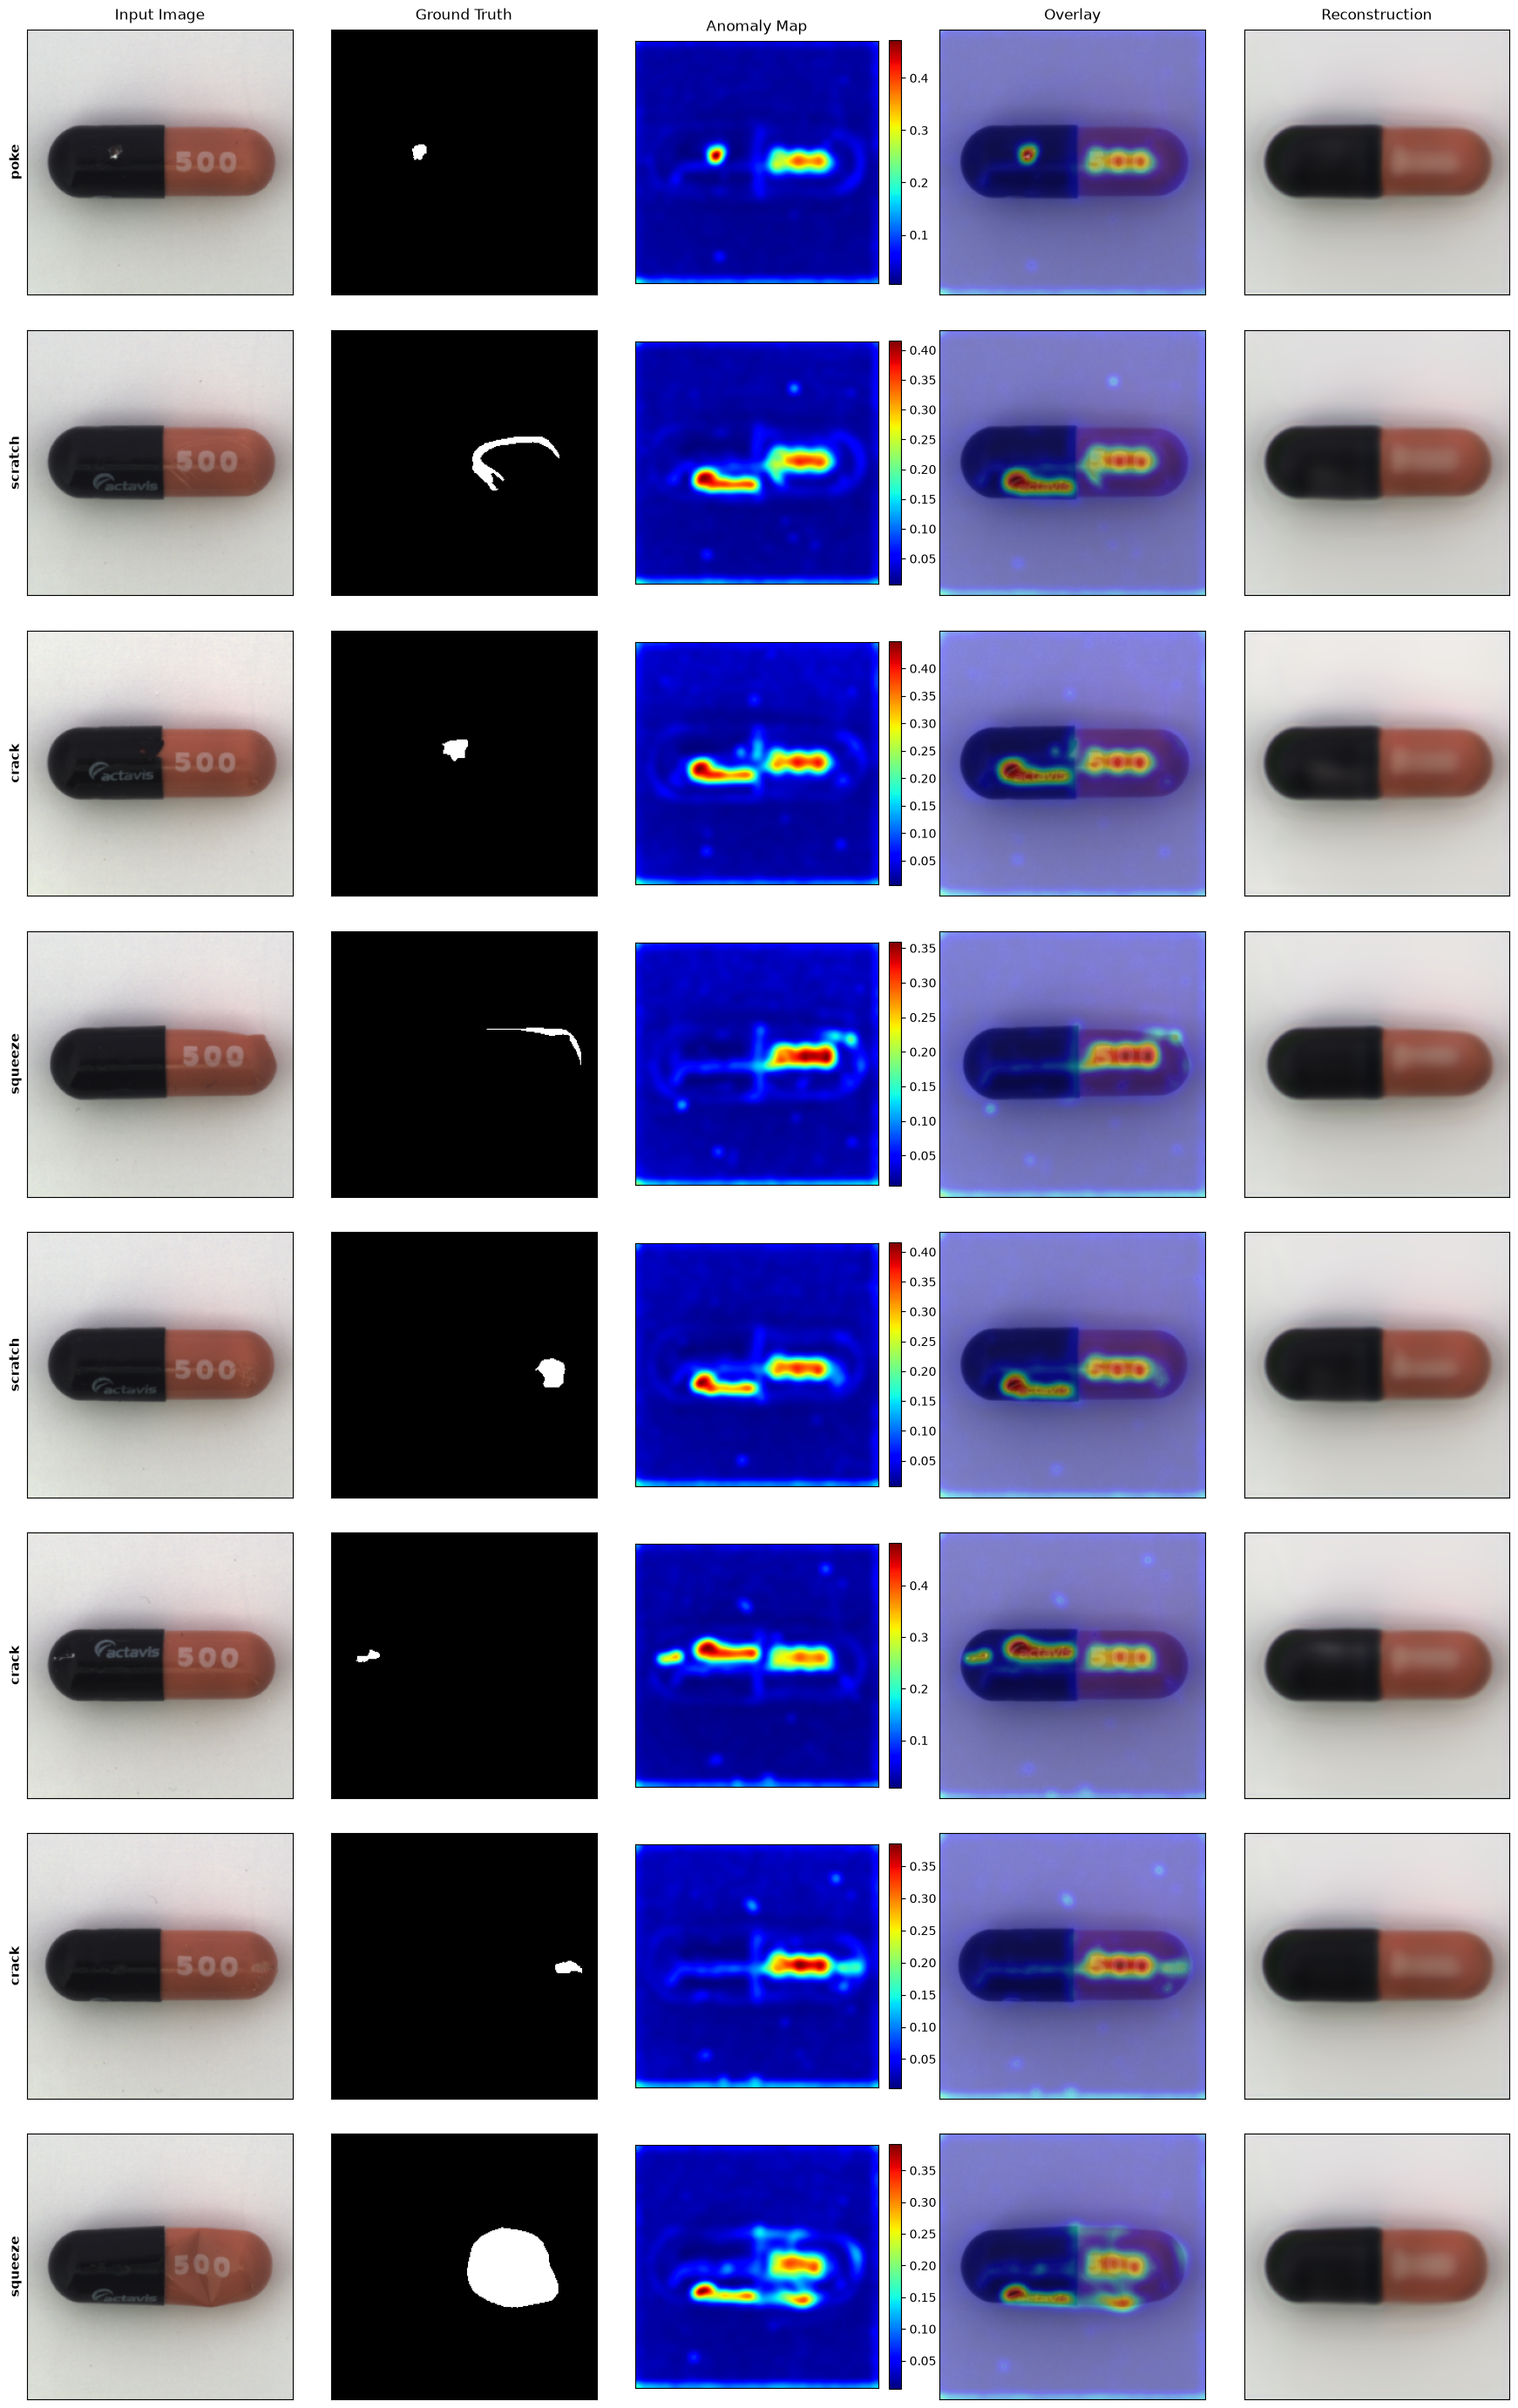

In [10]:
object_name = "capsule"  # Change this to the desired object name
checkpoint_path = f"experiments/pixel_reconstruction/{config['experiment_name']}/{object_name}/checkpoints/best_model.pth"

_, _, test_loader = build_dataloaders(object_name, config)
model = build_model(config, DEVICE, checkpoint_path=checkpoint_path)
visualize_anomalies(model, test_loader, DEVICE, visualize_reconstruction=True, num_samples=8)